In [1]:
# Installs the HuggingFace datasets library
# !pip install datasets

In [2]:
# Install contractions library for expanding shortened words (e.g. don't -> do not)
!pip install contractions

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 345.1/345.1 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 8.0 MB/s eta 0:00:00


In [3]:
from datasets import load_dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import re
import string
import contractions


from sklearn.model_selection import train_test_split

In [4]:
# Import plotly library
import plotly.graph_objects as go

In [5]:
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords')

nltk_stopwords = set(stopwords.words('english'))

keep_words = {"no", "not", "nor", "ain", "aren", "aren't", "couldn", "couldn't", "didn", "didn't", "doesn", "doesn't", "don", "don't", "hadn",
              "hadn't", "hasn", "hasn't", "haven", "haven't", "isn", "isn't", "mightn", "mightn't", "mustn", "mustn't", "needn", "needn't", "shan",
              "shan't", "shouldn", "shouldn't", "wasn", "wasn't", "weren", "weren't", "won", "won't", "wouldn", "wouldn't", "but", "however",
              "although", "though", "while", "yet", "only", "just", "still", "if", "should", "can", "might", "what", "when", "where", "which",
              "who", "whom", "why", "how", "very", "more", "most", "own", "same"}

# Words not in NLTK stopwords that we still want to remove
extra_remove_words = {"well", "think", "going", "thing", "know", "look"}

nltk_stopwords.update(extra_remove_words)
remove_stopwords = nltk_stopwords - keep_words

print(f"nltk_stopwords sum: {len(nltk_stopwords)}")
print(f"keep_words sum: {len(keep_words)}")
print(f"extra_remove_words sum: {len(extra_remove_words)}")
print(f"final remove_stopwords sum: {len(remove_stopwords)}")

nltk_stopwords sum: 204
keep_words sum: 66
extra_remove_words sum: 6
final remove_stopwords sum: 144


[nltk_data] Downloading package stopwords to /usr/share/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [6]:
dataset = load_dataset("ailsntua/QEvasion")

train_df = dataset["train"].to_pandas()
test_df = dataset["test"].to_pandas()

print("Train columns:", train_df.columns.tolist())
print("Test columns:", test_df.columns.tolist())
train_df.head(2)

README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/3.90M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/259k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/3448 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/308 [00:00<?, ? examples/s]

Train columns: ['title', 'date', 'president', 'url', 'question_order', 'interview_question', 'interview_answer', 'gpt3.5_summary', 'gpt3.5_prediction', 'question', 'annotator_id', 'annotator1', 'annotator2', 'annotator3', 'inaudible', 'multiple_questions', 'affirmative_questions', 'index', 'clarity_label', 'evasion_label']
Test columns: ['title', 'date', 'president', 'url', 'question_order', 'interview_question', 'interview_answer', 'gpt3.5_summary', 'gpt3.5_prediction', 'question', 'annotator_id', 'annotator1', 'annotator2', 'annotator3', 'inaudible', 'multiple_questions', 'affirmative_questions', 'index', 'clarity_label', 'evasion_label']


,title,date,president,url,question_order,interview_question,interview_answer,gpt3.5_summary,gpt3.5_prediction,question,annotator_id,annotator1,annotator2,annotator3,inaudible,multiple_questions,affirmative_questions,index,clarity_label,evasion_label
0,"The President's News Conference in Hanoi, Vietnam","September 10, 2023",Joseph R. Biden,https://www.presidency.ucsb.edu/documents/the-...,1,Q. Of the Biden administration. And accused th...,"Well, look, first of all, theI am sincere abou...",The question consists of 2 parts: \n1. How wou...,Question part: 1. How would you respond to the...,How would you respond to the accusation that t...,85,None,None,None,False,False,False,0,Clear Reply,Explicit
1,"The President's News Conference in Hanoi, Vietnam","September 10, 2023",Joseph R. Biden,https://www.presidency.ucsb.edu/documents/the-...,1,Q. Of the Biden administration. And accused th...,"Well, look, first of all, theI am sincere abou...",The question consists of 2 parts: \n1. How wou...,Question part: 1. How would you respond to the...,Do you think President Xi is being sincere abo...,85,None,None,None,False,False,False,1,Ambivalent,General


In [7]:
# with open('test_df.txt', 'w') as file:
#     file.write("Id,Predicted\n")
#     for i, label in enumerate(test_df['clarity_label']):
#         file.write(str(i) + "," + str(label) + "\n")

In [8]:
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

print("\nLabel distribution (Train):")
print(train_df["clarity_label"].value_counts())

print("\nLabel distribution (Test):")
print(test_df["clarity_label"].value_counts())

Train shape: (3448, 20)
Test shape: (308, 20)

Label distribution (Train):
clarity_label
Ambivalent         2040
Clear Reply        1052
Clear Non-Reply     356
Name: count, dtype: int64

Label distribution (Test):
clarity_label
Ambivalent         206
Clear Reply         79
Clear Non-Reply     23
Name: count, dtype: int64


In [9]:
train_df[["question", "interview_answer"]].head(10)

,question,interview_answer
0,How would you respond to the accusation that t...,"Well, look, first of all, theI am sincere abou..."
1,Do you think President Xi is being sincere abo...,"Well, look, first of all, theI am sincere abou..."
2,Do you believe the country's slowdown and gro...,"Look, I think China has a difficult economic p..."
3,Are you worried about the meeting between Pre...,"Look, I think China has a difficult economic p..."
4,Is the President's engagement with Asian coun...,"Well, I hope I get to see Mr. Xi sooner than l..."
5,Is there a danger of a cold war?,"Well, I hope I get to see Mr. Xi sooner than l..."
6,When will the President meet Mr. Xi?,"Well, I hope I get to see Mr. Xi sooner than l..."
7,How concerned are you about this lack of cons...,It wasn't so much an agreement that we would t...
8,Concerns about the lack of communication betw...,It's not a wedge issue of the Global South. It...
9,Inquiry about the reaction of Kyiv regarding ...,It's not a wedge issue of the Global South. It...


# **Data Cleaning**

In [10]:
def drop_conflicting_labels(df, name):
    # Find (question, answer) pairs with conflicting clarity labels across different annotators
    label_counts = df.groupby(["question", "interview_answer"])["clarity_label"].nunique()

    conflicting_pairs = label_counts[label_counts > 1].reset_index()
    conflicting_pairs.columns = ["question", "interview_answer", "unique_label_count"]

    print(f"Number of (question, answer) pairs with conflicting labels: {len(conflicting_pairs)}\n")

    # Drop (question, answer) pairs with conflicting clarity labels from the dataframe
    print(f"{name} size before dropping conflicting pairs: {len(df)}")

    df_clean = df.groupby(["question", "interview_answer"]).filter(
        lambda x: x["clarity_label"].nunique() == 1
    ).reset_index(drop=True)

    print(f"{name} size after dropping conflicting pairs: {len(df_clean)}\n")
    return df_clean

In [11]:
train_df = drop_conflicting_labels(train_df, "train_df")

Number of (question, answer) pairs with conflicting labels: 12

train_df size before dropping conflicting pairs: 3448
train_df size after dropping conflicting pairs: 3424



In [12]:
# test_df = drop_conflicting_labels(test_df, name="test_df")

In [13]:
def drop_inaudible(df, name):
    # Drop rows where inaudible = True
    print(f"Number of inaudible rows: {df['inaudible'].sum()}\n")

    print(f"{name} size before dropping inaudible rows: {len(df)}")

    df_clean = df[df["inaudible"] == False].reset_index(drop=True)

    print(f"{name} size after dropping inaudible rows: {len(df_clean)}\n")
    return df_clean

In [14]:
train_df = drop_inaudible(train_df, name="train_df")

Number of inaudible rows: 45

train_df size before dropping inaudible rows: 3424
train_df size after dropping inaudible rows: 3379



In [15]:
# test_df = drop_inaudible(test_df, name="test_df")

# **Text Preprocessing**

In [16]:
# Text Preprocessing Part only for the columns "question" and "interview_answer"

def text_preprocessing(text):

    # Lowercasing Part
    text = text.lower()

    # Expand contractions (don't -> do not)
    text = contractions.fix(text)

    # Replace em dash with space
    text = text.replace("—", " ")
    # Remove special unicode characters
    text = text.encode("ascii", "ignore").decode("ascii")

    # Remove punctuation (? . , ! : ;)
    text = text.translate(str.maketrans(string.punctuation, " " * len(string.punctuation)))

    # Remove stopwords
    text = " ".join([word for word in text.split() if word not in remove_stopwords])

    # Remove extra whitespaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Apply to both train and test
train_df["question"] = train_df["question"].apply(text_preprocessing)
train_df["interview_answer"] = train_df["interview_answer"].apply(text_preprocessing)

test_df["question"] = test_df["question"].apply(text_preprocessing)
test_df["interview_answer"] = test_df["interview_answer"].apply(text_preprocessing)


train_df[["question", "interview_answer"]].head(10)

,question,interview_answer
0,how would respond accusation united states con...,first thei sincere getting relationship right ...
1,president xi sincere getting relationship back...,first thei sincere getting relationship right ...
2,believe country slowdown growth could risk des...,china difficult economic problem right whole r...
3,worried meeting president putin kim jong un if...,china difficult economic problem right whole r...
4,president engagement asian countries sign cold...,hope get see mr xi sooner later spent more tim...
5,danger cold war,hope get see mr xi sooner later spent more tim...
6,when president meet mr xi,hope get see mr xi sooner later spent more tim...
7,how concerned lack consensus,not much agreement would try meet goals g 20 u...
8,concerns lack communication interviewee presid...,not wedge issue global south wedge issue russi...
9,inquiry reaction kyiv regarding g 20 communiqu...,not wedge issue global south wedge issue russi...


In [17]:
# Display rows from the train_df where in interview_answer column has 5 or fewer words

pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", None)

train_df["answer_word_count"] = train_df["interview_answer"].apply(lambda x: len(x.split()))

train_df_sorted = train_df[train_df["answer_word_count"] <= 5].sort_values("answer_word_count", ascending=True).reset_index(drop=True)

display(train_df_sorted[["question", "interview_answer", "answer_word_count", "clarity_label"]])

pd.reset_option("display.max_rows")
pd.reset_option("display.max_colwidth")

,question,interview_answer,answer_word_count,clarity_label
0,how say merry christmas hawaii,,0,Clear Reply
1,discussion venezuela,,0,Clear Reply
2,seen video,,0,Clear Reply
3,russia security assistance ukraine,,0,Ambivalent
4,virtual summit participation,yes,1,Clear Reply
5,what tax cuts,keil,1,Ambivalent
6,inquiring belief ramp vladimir putin,yes,1,Clear Reply
7,still complete confidence,yes,1,Clear Reply
8,inquiry speaker opinion whether hillary clinton nominee,pardon,1,Clear Non-Reply
9,what perpetrators rwandan genocide who remain large walking freely,yes,1,Ambivalent


In [18]:
test_df["answer_word_count"] = test_df["interview_answer"].apply(lambda x: len(x.split()))

test_df_sorted = test_df[test_df["answer_word_count"] <= 5].sort_values("answer_word_count", ascending=True).reset_index(drop=True)

display(test_df_sorted[["question", "interview_answer", "answer_word_count", "clarity_label"]])

,question,interview_answer,answer_word_count,clarity_label
0,permission direct question president hu,course,1,Clear Reply
1,what kind punishment would like see imposed no...,okay,1,Ambivalent
2,would campaign mike fitzpatrick,already,1,Clear Reply
3,decision g 20 counterparts endorse stiff defic...,okay,1,Ambivalent
4,can go back north korea mr president,please,1,Clear Reply
5,clarification stance towards nuclear north korea,no,1,Clear Reply
6,make break issue terms domestic politics,already,1,Ambivalent
7,confidence republicans holding house senate,yes,1,Clear Reply
8,previous conversations prime minister maliki f...,iran,1,Clear Non-Reply
9,would campaign senator joe lieberman iraq,stay connecticut,2,Ambivalent


In [19]:
print(f"train_df size before dropping: {len(train_df)}")

# Drop rows with 0 words in the answer
train_df = train_df[train_df["answer_word_count"] > 0].reset_index(drop=True)

print(f"train_df size after dropping: {len(train_df)}")

train_df size before dropping: 3379
train_df size after dropping: 3375


In [20]:
print(f"test_df size before dropping: {len(test_df)}")

# Drop rows with 0 words in the answer
test_df = test_df[test_df["answer_word_count"] > 0].reset_index(drop=True)

print(f"test_df size after dropping: {len(test_df)}")

test_df size before dropping: 308
test_df size after dropping: 308


# **EDA part**

In [21]:
print(train_df["president"].unique())
print(f"\nTotal unique presidents: {train_df['president'].nunique()}")

['Joseph R. Biden' 'Donald J. Trump' 'Barack Obama' 'George W. Bush']

Total unique presidents: 4


In [22]:
print(train_df["clarity_label"].unique())

['Clear Reply' 'Ambivalent' 'Clear Non-Reply']


In [23]:
# Plot grouped bar chart showing the distribution of clarity labels per president
def plot_label_distribution_per_president(df):
    labels = ["Clear Reply", "Ambivalent", "Clear Non-Reply"]
    colors = ["#2196F3", "#FF9800", "#F44336"]

    grouped = df.groupby(["president", "clarity_label"]).size().unstack(fill_value=0)

    presidents = grouped.index.tolist()

    fig = go.Figure(data=[
        go.Bar(
            name=label,
            x=presidents,
            y=grouped[label].tolist(),
            marker_color=color
        )
        for label, color in zip(labels, colors)
    ])

    fig.update_layout(
        barmode="group",
        title="Clarity Label Distribution per President",
        yaxis_title="Count",
        legend_title="Clarity Label",
    )

    fig.update_xaxes(
        tickangle=0,
        tickfont=dict(size=12, color="black"),
        title_text="President",
        title_standoff=40
    )

    fig.show()

plot_label_distribution_per_president(train_df)

In [24]:
# Plot pie chart showing the overall distribution of clarity labels across all presidents
def plot_label_distribution_pie(df):
    labels = ["Clear Reply", "Ambivalent", "Clear Non-Reply"]
    colors = ["#2196F3", "#FF9800", "#F44336"]

    label_counts = df["clarity_label"].value_counts()
    values = [label_counts[label] for label in labels]

    fig = go.Figure(data=[go.Pie(labels=labels, values=values)])

    fig.update_traces(
        hoverinfo='label+percent',
        texttemplate='%{percent}<br>%{value}',
        textfont_size=20,
        marker=dict(colors=colors, line=dict(color='#000000', width=2))
    )

    fig.update_layout(
        title=dict(
          text="Overall Clarity Label Distribution",
          font=dict(size=24, family="Arial Black")
        ),
        legend_title="Clarity Label"
    )

    fig.show()

plot_label_distribution_pie(train_df)

In [25]:
plot_label_distribution_pie(test_df)

In [26]:
# Plot pie chart showing the distribution of interview answers per president
def plot_answer_distribution_per_president(df):

    president_counts = df["president"].value_counts()

    presidents = president_counts.index.tolist()
    values = president_counts.values.tolist()

    color_map = {
        "Donald J. Trump": "#EF553B",
        "Barack Obama":    "#636EFA",
        "George W. Bush":  "#00CC96",
        "Joseph R. Biden": "#AB63FA",
    }

    colors = [color_map[p] for p in presidents]

    fig = go.Figure(data=[go.Pie(labels=presidents, values=values)])

    fig.update_traces(
        hoverinfo='label+percent',
        texttemplate='%{percent}<br>%{value}',
        textfont_size=14,
        marker=dict(colors=colors, line=dict(color='#000000', width=2))
    )

    fig.update_layout(
        title=dict(
            text="Interview Answer Distribution per President",
            font=dict(size=24, family="Arial Black")
        ),
        legend_title="President"
    )

    fig.show()

plot_answer_distribution_per_president(train_df)

In [27]:
# Table and grouped bar chart showing answer length statistics (average, median, min, max) per clarity label
def print_length_statistics(df):
    labels = ["Clear Reply", "Ambivalent", "Clear Non-Reply"]
    rows = []

    for label in labels:
        subset = df[df["clarity_label"] == label]["interview_answer"]
        lengths = subset.apply(lambda x: len(x.split()))

        rows.append({
            "Label": label,
            "Average Length": round(lengths.mean(), 1),
            "Median": round(lengths.median(), 1),
            "Min": lengths.min(),
            "Max": lengths.max()
        })

    result_df = pd.DataFrame(rows).set_index("Label")
    display(result_df)

    print("\n\n")

    metrics = ["Max", "Average Length", "Median", "Min"]
    colors  = ["#F44336", "#FF9800", "#2196F3", "#FFEB3B"]

    fig = go.Figure(data=[
        go.Bar(
            name=metric,
            x=labels,
            y=[row[metric] for row in rows],
            text=[row[metric] for row in rows],
            textposition="outside",
            marker_color=color
        )
        for metric, color in zip(metrics, colors)
    ])

    fig.update_layout(
        barmode="group",
        title=dict(
            text="Answer Length Statistics per Clarity Label",
            font=dict(size=24, family="Arial Black")
        ),
        yaxis_title="Length (words)",
        legend_title="Metric",
    )

    fig.update_xaxes(
        tickangle=0,
        tickfont=dict(size=12, color="black"),
        title_text="Clarity Label",
        title_standoff=40
    )

    fig.show()

print_length_statistics(train_df)

,Average Length,Median,Min,Max
Label,,,,
Clear Reply,134.6,96.5,1,767
Ambivalent,164.6,119.0,1,1015
Clear Non-Reply,67.6,19.0,1,755


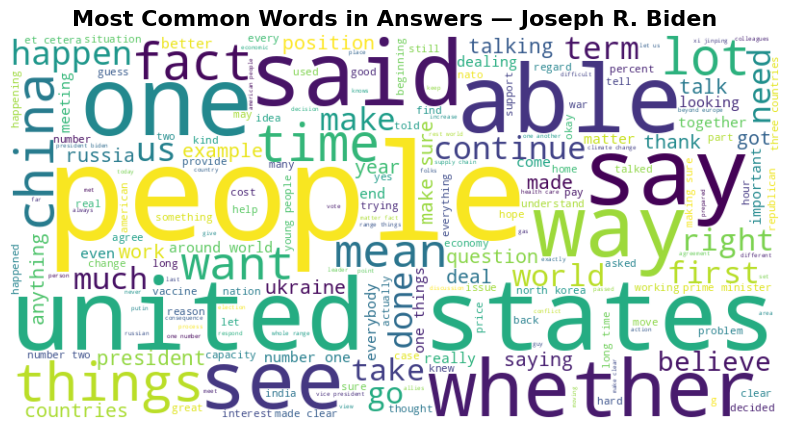

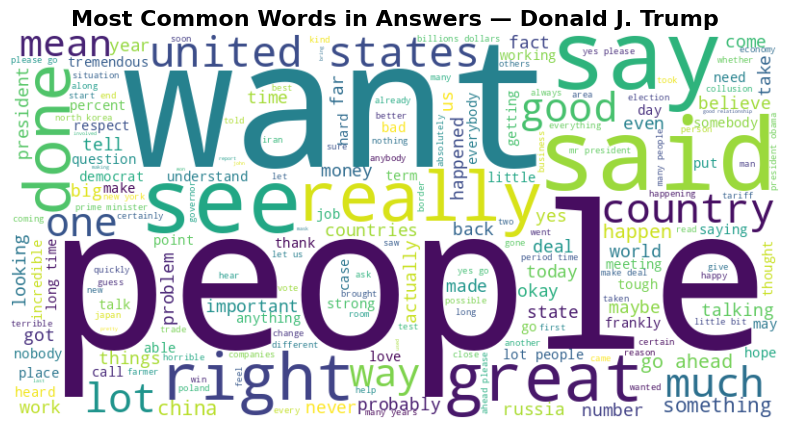

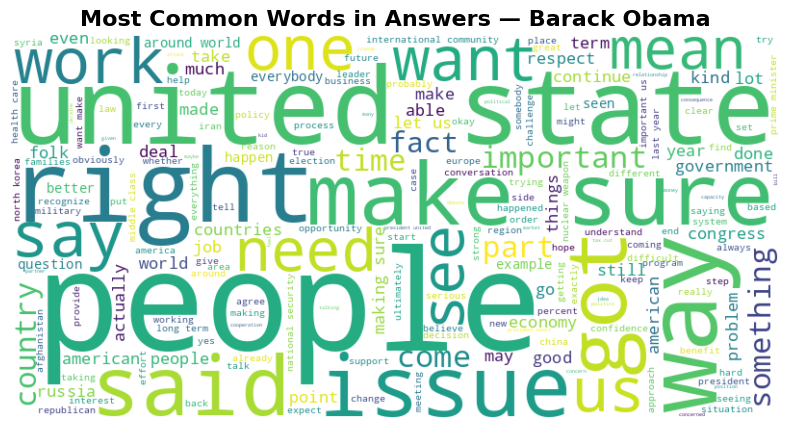

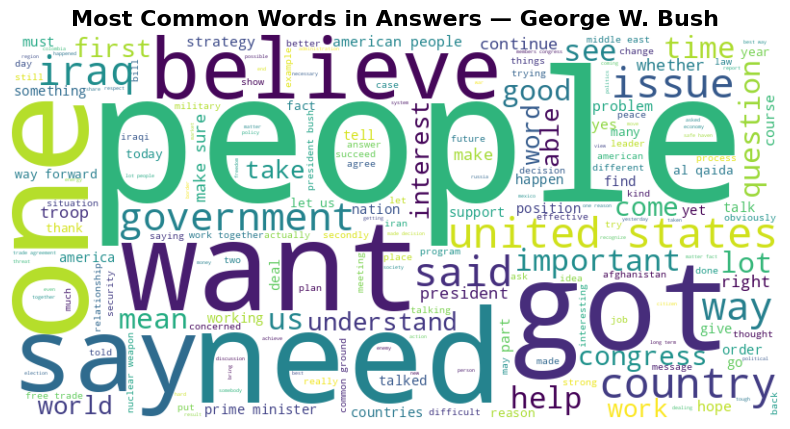

In [28]:
from wordcloud import WordCloud

# word cloud showing the most frequently used words in interview answers per president
def generate_word_cloud(text_data, title):
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text_data)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis("off")
    plt.title(title, fontsize=16, fontweight='bold')
    plt.show()

def generate_wordclouds_per_president(df):
    presidents = df["president"].unique()

    for president in presidents:
        president_df = df[df["president"] == president]

        answer_text = ' '.join(president_df["interview_answer"].dropna().astype(str))
        generate_word_cloud(answer_text, f'Most Common Words in Answers — {president}')
        print("\n")

generate_wordclouds_per_president(train_df)

In [29]:
from collections import Counter

pd.set_option("display.max_rows", None)

# Table showing the top N most frequently used words per clarity label
def print_top_tokens_per_label(df, top_n):

    labels = ["Clear Reply", "Ambivalent", "Clear Non-Reply"]

    for label in labels:
        subset = df[df["clarity_label"] == label]
        all_text = " ".join(subset["interview_answer"].astype(str).tolist())

        tokens = all_text.split()

        most_common = Counter(tokens).most_common(top_n)

        result_df = pd.DataFrame(most_common, columns=["Word", "Count"])
        result_df.index = result_df.index + 1

        print(f"\n\n\nTop {top_n} frequently Words in {label} label:\n")
        display(result_df)

print_top_tokens_per_label(train_df, 100)

pd.reset_option("display.max_rows")




Top 100 frequently Words in Clear Reply label:



,Word,Count
1,not,3690
2,but,2007
3,what,1680
4,people,1613
5,very,1285
6,if,1091
7,would,1026
8,can,985
9,just,833
10,one,800





Top 100 frequently Words in Ambivalent label:



,Word,Count
1,not,8620
2,but,4804
3,what,4130
4,people,3432
5,very,3140
6,if,2619
7,can,2461
8,would,2386
9,just,1844
10,us,1820





Top 100 frequently Words in Clear Non-Reply label:



,Word,Count
1,not,833
2,but,380
3,what,366
4,very,248
5,people,234
6,would,189
7,if,189
8,can,170
9,just,143
10,make,140


# **Combined Text Column Creation Part**

## **Concatenates the question and answer into a single string using the following format:**
## **question: [question text] answer: [answer text]**

In [30]:
train_df["concat"] = "question: " + train_df["question"] + " answer: " + train_df["interview_answer"]

texts  = train_df["concat"]
labels = train_df["clarity_label"]

test_df["concat"] = "question: " + test_df["question"] + " answer: " + test_df["interview_answer"]

# **TF-IDF + Logistic Regression part**

In [31]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
import numpy as np

In [32]:
X_train_tfidf, X_validation_tfidf, y_train_tfidf, y_validation_tfidf = train_test_split(
    texts, labels, test_size=0.15, random_state=42, stratify=labels # the stratify=labels preserves class distribution in both train and validation sets
)

print(f"Training samples: {len(X_train_tfidf)}")
print(f"Validation samples: {len(X_validation_tfidf)}")

Training samples: 2868
Validation samples: 507


# **Thought Process Explanation:**

In the following section we use the baseline code provided by the lab adapted for the needs of this assignment. The model is trained with manually set initial parameters (C=0.5, ngram_range=(1,2)). However finding the best parameter combination manually by trial and error is impractical. For this reason in the next section we use GridSearchCV which automatically tries all possible combinations of the parameters we provide and returns the combination that achieves the best macro F1 score.

&nbsp;


So the baseline model and the GridSearch model are trained independently.
The baseline serves as a reference point with manually set parameters
while GridSearch optimizes the parameters automatically


In [33]:
# Baseline model: adapted from the lab code trained with manually set initial parameters

tfidf_vectorizer = TfidfVectorizer(
    # extract single words (unigrams) and word pairs (bigrams) as features e.g. "not clear" -> ["not", "clear", "not clear"]
    ngram_range=(1, 2),

    # replace raw word count with 1+log(count) to prevent repeated words from dominating
    sublinear_tf=True
)

X_train_tfidf_vec = tfidf_vectorizer.fit_transform(X_train_tfidf)
X_val_tfidf_vec = tfidf_vectorizer.transform(X_validation_tfidf)

tfidf_classifier = LogisticRegression(
    # sets the maximum number of iterations the optimizer is allowed to run when finding the best model weights
    max_iter=1000,

    # controls regularization strength. Regularization helping prevent overfitting
    C=0.5,

    # gives higher weight to minority classes to handle class imbalance
    class_weight='balanced',
    random_state=42
)
tfidf_classifier.fit(X_train_tfidf_vec, np.ravel(y_train_tfidf))
print(y_train_tfidf)
print(np.ravel(y_train_tfidf))

2642         Ambivalent
3345        Clear Reply
1993         Ambivalent
2314         Ambivalent
2880        Clear Reply
             ...       
19           Ambivalent
180     Clear Non-Reply
651         Clear Reply
3262        Clear Reply
1128         Ambivalent
Name: clarity_label, Length: 2868, dtype: object
['Ambivalent' 'Clear Reply' 'Ambivalent' ... 'Clear Reply' 'Clear Reply'
 'Ambivalent']


In [34]:
results = tfidf_classifier.predict(X_train_tfidf_vec)
correct_predictions = sum(p == g for p, g in zip(results, y_train_tfidf))
n = X_train_tfidf_vec.shape[0]
print(f"Correct predictions: {correct_predictions}/{n} ({correct_predictions/n * 100:.2f}%)")

Correct predictions: 2498/2868 (87.10%)


F1 Score: (train) 0.98 vs 0.36 (val)
F1 Score: (train) 0.97 vs 0.39 (val)
F1 Score: (train) 0.96 vs 0.45 (val)
F1 Score: (train) 0.94 vs 0.47 (val)
F1 Score: (train) 0.93 vs 0.48 (val)
F1 Score: (train) 0.92 vs 0.49 (val)
F1 Score: (train) 0.89 vs 0.49 (val)
F1 Score: (train) 0.88 vs 0.49 (val)
F1 Score: (train) 0.87 vs 0.50 (val)


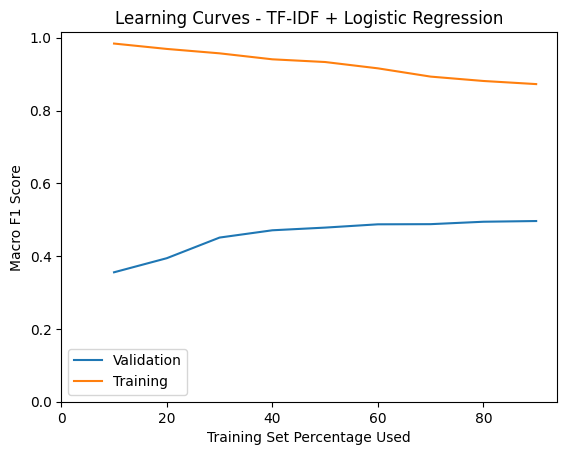

In [35]:
list_f1 = []
list_f1_train = []
list_sample_size = []

# Learning curve: train the model 9 times on growing subsets (10% to 90%) of training data
# to see how performance changes as more data is added
for times in range(9):
    X_subset, _, y_subset, _ = train_test_split(
        X_train_tfidf, y_train_tfidf,
        test_size=1 - (times * 0.1 + 0.1),
        random_state=42,
        # use training labels to preserve class distribution in each subset
        stratify=y_train_tfidf
    )

    tfidf_vec = TfidfVectorizer(
        # extract single words (unigrams) and word pairs (bigrams) as features e.g. "not clear" -> ["not", "clear", "not clear"]
        ngram_range=(1, 2),

        # replace raw word count with 1+log(count) to prevent repeated words from dominating
        sublinear_tf=True
    )
    X_subset_vec = tfidf_vec.fit_transform(X_subset)
    X_val_vec = tfidf_vec.transform(X_validation_tfidf)

    clf = LogisticRegression(
        # sets the maximum number of iterations the optimizer is allowed to run when finding the best model weights
        max_iter=1000,

        # controls regularization strength. Regularization helping prevent overfitting
        C=0.5,

        # gives higher weight to minority classes to handle class imbalance
        class_weight='balanced',
        random_state=42
    )
    clf.fit(X_subset_vec, np.ravel(y_subset))

    results_train = clf.predict(X_subset_vec)
    results_val = clf.predict(X_val_vec)


    # average='macro' compute F1 per class then average equally treating all 3 classes the same regardless of size
    f1_train = f1_score(y_subset, results_train, average='macro')
    f1_val = f1_score(y_validation_tfidf, results_val, average='macro')

    print(f"F1 Score: (train) {f1_train:.2f} vs {f1_val:.2f} (val)")

    list_f1.append(f1_val)
    list_f1_train.append(f1_train)
    list_sample_size.append((times * 0.1 + 0.1) * 100)

plt.plot(list_sample_size, list_f1)
plt.plot(list_sample_size, list_f1_train)
plt.title("Learning Curves - TF-IDF + Logistic Regression")
plt.xlim(xmin=0)
plt.ylim(ymin=0)
plt.xlabel("Training Set Percentage Used")
plt.ylabel("Macro F1 Score")
plt.legend(["Validation", "Training"])
plt.show()

In [36]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline

# Cross validation: train and evaluate the model 5 times on different splits
# to get a more reliable estimate of performance than a single train/val split
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1,2), sublinear_tf=True)),
    ('clf', LogisticRegression(max_iter=1000, C=0.5, class_weight='balanced', random_state=42))
])

scores = cross_val_score(pipeline, X_train_tfidf, y_train_tfidf, cv=5, scoring='f1_macro')
print(f"Cross validation F1 scores: {', '.join(f'{s:.2f}' for s in scores)}")
print(f"Mean F1: {scores.mean():.2f}")

Cross validation F1 scores: 0.54, 0.54, 0.57, 0.59, 0.53
Mean F1: 0.55


In [37]:
from sklearn.metrics import classification_report

# Classification report: evaluate the trained model on the validation set
# to get precision, recall and f1-score per class (Clear Reply, Ambivalent, Clear Non-Reply)

# Use the trained tfidf_classifier to predict labels on the validation set
predictions = tfidf_classifier.predict(X_val_tfidf_vec)
# gold = the true labels
gold = y_validation_tfidf

# shows precision, recall and f1 for each class separately (Clear Reply, Ambivalent, Clear Non-Reply)
# precision = out of all predictions for a class how many were correct
# recall = out of all actual samples of a class how many did the model find
print(classification_report(gold, predictions))

# average='macro' compute F1 per class then average equally treating all 3 classes the same regardless of size
macro_f1 = f1_score(gold, predictions, average='macro')
print(f"Macro F1: {macro_f1:.4f}")

                 precision    recall  f1-score   support

     Ambivalent       0.68      0.67      0.68       301
Clear Non-Reply       0.42      0.42      0.42        52
    Clear Reply       0.43      0.44      0.43       154

       accuracy                           0.58       507
      macro avg       0.51      0.51      0.51       507
   weighted avg       0.58      0.58      0.58       507

Macro F1: 0.5114


## **The model used for final predictions: TF-IDF + Logistic Regression with GridSearchCV to find the best parameters**

In [38]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

# GridSearch: automatically find the best combination of parameters
# by trying all combinations and evaluating each with 5-fold cross validation
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(sublinear_tf=True)),
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])

param_grid = [
    # L2 penalty
    {
        'tfidf__ngram_range': [(1,1), (1,2)],
        # 'tfidf__min_df': [3, 5], # dont use this line you make a worse f1 score 0.4663
        # 'tfidf__max_features': [10000],
        # 'tfidf__max_df': [0.85, 0.90, 0.95], # its not worth it I don't get a bigger difference in better results with that and its take a significant more time ie i take f1 score 0.4789
        'clf__C': [0.5, 0.7, 0.8, 0.9, 1.0, 1.5],
        # 'clf__C': [0.9],
        'clf__solver': ['lbfgs', 'liblinear', 'saga'],
        'clf__penalty': ['l2'],
        'clf__class_weight': ['balanced']
    },
    # L1 penalty only compatible with liblinear and saga
    {
        'tfidf__ngram_range': [(1,1), (1,2)],
        # 'tfidf__min_df': [3, 5], # # dont use this line you make a worse f1 score 0.4663
        # 'tfidf__max_features': [10000],
        # 'tfidf__max_df': [0.85, 0.90, 0.95], # its not worth it I don't get a bigger difference in better results with that and its take a significant more time ie i take f1 score 0.4789
        'clf__C': [0.5, 0.7, 0.8, 0.9, 1.0, 1.5],
        # 'clf__C': [0.9],
        'clf__solver': ['liblinear', 'saga'],
        'clf__penalty': ['l1'],
        'clf__class_weight': ['balanced']
    }
]

grid_search = GridSearchCV(
    pipeline,
    param_grid, # list of 2 grids to try all combinations
    cv=5, # 5 fold cross validation for each combination
    scoring='f1_macro',
    n_jobs=-1, # use all CPU cores to speed up
    verbose=1 # print progress
)

grid_search.fit(X_train_tfidf, y_train_tfidf)

print(f"Best parameters: {grid_search.best_params_}")
print(f"Best Macro F1: {grid_search.best_score_:.4f}")

Fitting 5 folds for each of 60 candidates, totalling 300 fits


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which 

Best parameters: {'clf__C': 0.9, 'clf__class_weight': 'balanced', 'clf__penalty': 'l2', 'clf__solver': 'lbfgs', 'tfidf__ngram_range': (1, 2)}
Best Macro F1: 0.5555


F1 Score: (train) 0.98 vs 0.34 (val)
F1 Score: (train) 0.97 vs 0.40 (val)
F1 Score: (train) 0.96 vs 0.43 (val)
F1 Score: (train) 0.94 vs 0.46 (val)
F1 Score: (train) 0.94 vs 0.47 (val)
F1 Score: (train) 0.92 vs 0.49 (val)
F1 Score: (train) 0.90 vs 0.50 (val)
F1 Score: (train) 0.89 vs 0.51 (val)
F1 Score: (train) 0.89 vs 0.50 (val)


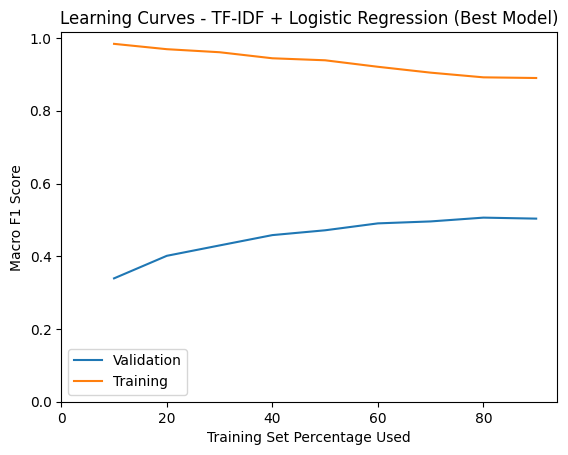

In [39]:
best_params = grid_search.best_params_

list_f1_grid = []
list_f1_train_grid = []
list_sample_size_grid = []

# Learning curve: train the best model from GridSearch 9 times on growing subsets (10% to 90%) of training data
# to see how performance changes as more data is added
for times in range(9):
    X_subset, _, y_subset, _ = train_test_split(
        X_train_tfidf, y_train_tfidf,
        test_size=1 - (times * 0.1 + 0.1),
        random_state=42,
        # use training labels to preserve class distribution in each subset
        stratify=y_train_tfidf
    )

    tfidf_vec = TfidfVectorizer(
        # use the best ngram_range found by GridSearch
        ngram_range=best_params['tfidf__ngram_range'],

        # replace raw word count with 1+log(count) to prevent repeated words from dominating
        sublinear_tf=True
    )
    X_subset_vec = tfidf_vec.fit_transform(X_subset)
    X_val_vec = tfidf_vec.transform(X_validation_tfidf)

    clf = LogisticRegression(
        max_iter=1000,
        random_state=42,
        # use the best parameters found by GridSearch
        C=best_params['clf__C'],
        solver=best_params['clf__solver'],
        penalty=best_params['clf__penalty'],
        class_weight='balanced'
    )
    clf.fit(X_subset_vec, np.ravel(y_subset))

    results_train = clf.predict(X_subset_vec)
    results_val = clf.predict(X_val_vec)

    # average='macro' compute F1 per class then average equally, treating all 3 classes the same regardless of size
    f1_train = f1_score(y_subset, results_train, average='macro')
    f1_val = f1_score(y_validation_tfidf, results_val, average='macro')

    print(f"F1 Score: (train) {f1_train:.2f} vs {f1_val:.2f} (val)")

    list_f1_grid.append(f1_val)
    list_f1_train_grid.append(f1_train)
    list_sample_size_grid.append((times * 0.1 + 0.1) * 100)

plt.plot(list_sample_size_grid, list_f1_grid)
plt.plot(list_sample_size_grid, list_f1_train_grid)
plt.title("Learning Curves - TF-IDF + Logistic Regression (Best Model)")
plt.xlim(xmin=0)
plt.ylim(ymin=0)
plt.xlabel("Training Set Percentage Used")
plt.ylabel("Macro F1 Score")
plt.legend(["Validation", "Training"])
plt.show()

In [40]:
# Evaluate the best model from GridSearch on the validation set
val_predictions = grid_search.best_estimator_.predict(X_validation_tfidf)
print(classification_report(y_validation_tfidf, val_predictions))
macro_f1 = f1_score(y_validation_tfidf, val_predictions, average='macro')
print(f"Best Model Validation Macro F1: {macro_f1:.4f}")

                 precision    recall  f1-score   support

     Ambivalent       0.67      0.68      0.68       301
Clear Non-Reply       0.43      0.38      0.41        52
    Clear Reply       0.44      0.45      0.44       154

       accuracy                           0.58       507
      macro avg       0.51      0.50      0.51       507
   weighted avg       0.58      0.58      0.58       507

Best Model Validation Macro F1: 0.5087


In [41]:
# Evaluate the best model from GridSearch on the test set
test_predictions = grid_search.best_estimator_.predict(test_df["concat"])
print(classification_report(test_df["clarity_label"], test_predictions))
print(f"Test Macro F1: {f1_score(test_df['clarity_label'], test_predictions, average='macro'):.4f}")

                 precision    recall  f1-score   support

     Ambivalent       0.70      0.78      0.74       206
Clear Non-Reply       0.35      0.26      0.30        23
    Clear Reply       0.32      0.25      0.28        79

       accuracy                           0.61       308
      macro avg       0.46      0.43      0.44       308
   weighted avg       0.58      0.61      0.59       308

Test Macro F1: 0.4413


In [42]:
# with open("submission.csv", "w") as file:
#     file.write("Id,Predicted\n")
#     for i, prediction in enumerate(test_predictions):
#         file.write(f"{i},{prediction}\n")

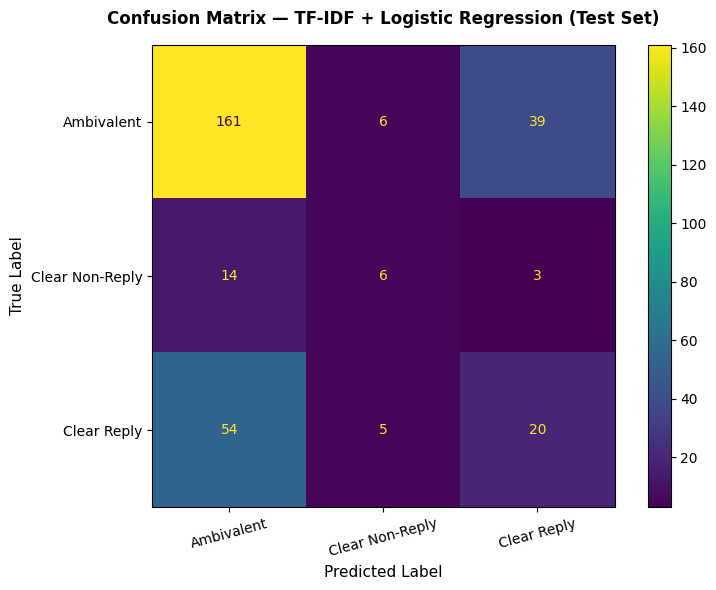



Confusion Matrix (raw counts):
Labels: ['Ambivalent', 'Clear Non-Reply', 'Clear Reply']
[[161   6  39]
 [ 14   6   3]
 [ 54   5  20]]


In [43]:
# Confusion Matrix Part: TF-IDF + Logistic Regression

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Get the true labels and predictions on the test set
y_true = test_df["clarity_label"]
y_pred = grid_search.best_estimator_.predict(test_df["concat"])

labels = ["Ambivalent", "Clear Non-Reply", "Clear Reply"]

# Compute the confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=labels)

# Plot the confusion matrix
fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(ax=ax, cmap="viridis", colorbar=True)

ax.set_title("Confusion Matrix — TF-IDF + Logistic Regression (Test Set)",
             fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel("Predicted Label", fontsize=11)
ax.set_ylabel("True Label", fontsize=11)

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

print("\n")
print("Confusion Matrix (raw counts):")
print(f"Labels: {labels}")
print(cm)

# **Word2Vec + Logistic Regression part**

# **Thought Process Explanation:**

In the following section the implementation is inspired by this website<br>
https://www.kaggle.com/code/kstathou/word-embeddings-logistic-regression


The two core ideas taken from that website are:

1. The document_vector function which converts a document into a single vector by averaging the Word2Vec vectors of its words and skipping OOV (Out Of Vocabulary) words that the model has not seen during training:
```python
    doc = [word for word in doc if word in w2v.wv.key_to_index]
    return np.mean(w2v.wv[doc], axis=0)
```

2. Training Word2Vec from scratch on our own data instead of using a pre-trained model like Google News. This allows the model to learn vectors that are specific to the context and vocabulary of our dataset

&nbsp;

Based on these two core ideas we extended them by adding several elements that were necessary to adapt them to the needs of our project

In [44]:
!pip install gdown gensim

In [45]:
import gensim
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, classification_report
from sklearn.model_selection import GridSearchCV, train_test_split

best_val_macro = 0
best_params = {}
best_estimator = None
best_X_test = None

for window in [10]:
    for vector_size in [650]:
        for epochs in [80]:

            print(50 * '*')
            print(f"window={window}, vector_size={vector_size}, epochs={epochs}")

            # Train Word2Vec from scratch on our data
            w2v = gensim.models.Word2Vec(
                list(train_df.concat.str.split()),
                vector_size = vector_size,
                window = window,
                min_count = 2,
                epochs = epochs,
                sg = 1,
                seed = 42,  # with that we fixes word2vec random initialization so results are the same every run
                workers = 1  # required for seed to work, single thread ensures full reproducibility
            )

            def document_vector(doc):
                """Create document vectors by averaging word vectors. Remove out-of-vocabulary words."""
                doc = [word for word in doc if word in w2v.wv.key_to_index]
                if not doc:
                    return np.zeros(vector_size)
                return np.mean(w2v.wv[doc], axis=0)

            # Vectorize train and test data
            X_train_vec = np.vstack(train_df.concat.str.split().apply(document_vector))
            X_test_vec = np.vstack(test_df.concat.str.split().apply(document_vector))
            y_train_all = train_df['clarity_label'].values

            # Train/Validation split
            X_train_vec, X_val_vec, y_train, y_val = train_test_split(
                X_train_vec, y_train_all,
                test_size = 0.15,
                random_state = 42,
                stratify = y_train_all
            )

            # GridSearch for best Logistic Regression parameters
            param_grid = [
                # L2 penalty
                {
                    'C': [0.3, 0.5, 0.7, 1.0],
                    'solver' : ['lbfgs', 'liblinear', 'saga'],
                    'penalty' : ['l2'],
                    'class_weight' : ['balanced']
                },
                # L1 penalty - only compatible with liblinear and saga
                {
                   'C': [0.3, 0.5, 0.7, 1.0],
                    'solver' : ['liblinear', 'saga'],
                    'penalty' : ['l1'],
                    'class_weight' : ['balanced']
                }
            ]

            gs = GridSearchCV(
                LogisticRegression(max_iter=10000, random_state=42),
                param_grid,
                cv = 5, # 5-fold cross validation
                scoring = 'f1_macro',
                n_jobs  = -1, # use all CPU cores
                verbose = 0
            )

            gs.fit(X_train_vec, y_train)

            # Evaluate best Logistic Regression on validation set
            val_preds = gs.best_estimator_.predict(X_val_vec)
            val_macro_f1 = f1_score(y_val, val_preds, average='macro')

            print(f"  Best Logistic Regression params : {gs.best_params_}")
            print(f"  Cross-Validation Macro F1 : {gs.best_score_:.4f}")
            print(f"  Validation Macro F1 : {val_macro_f1:.4f}")

            # Track best overall combination
            if val_macro_f1 > best_val_macro:
                best_val_macro = val_macro_f1
                best_params = {
                    'window' : window,
                    'vector_size' : vector_size,
                    'epochs' : epochs,
                    'lr_params' : gs.best_params_
                }
                best_estimator = gs.best_estimator_
                best_X_test = X_test_vec


# Final results
print(50 * '*')
print(f"Best overall params : {best_params}")
print(f"Best Validation Macro F1   : {best_val_macro:.4f}")

# Evaluate best model on test set
test_predictions = best_estimator.predict(best_X_test)
print(classification_report(test_df['clarity_label'], test_predictions))
print(f"Test Macro F1: {f1_score(test_df['clarity_label'], test_predictions, average='macro'):.4f}")

with open("submission.csv", "w") as file:
    file.write("Id,Predicted\n")
    for i, prediction in enumerate(test_predictions):
        file.write(f"{i},{prediction}\n")

**************************************************
window=10, vector_size=650, epochs=80
  Best Logistic Regression params : {'C': 0.7, 'class_weight': 'balanced', 'penalty': 'l2', 'solver': 'liblinear'}
  Cross-Validation Macro F1 : 0.4829
  Validation Macro F1 : 0.4689
**************************************************
Best overall params : {'window': 10, 'vector_size': 650, 'epochs': 80, 'lr_params': {'C': 0.7, 'class_weight': 'balanced', 'penalty': 'l2', 'solver': 'liblinear'}}
Best Validation Macro F1   : 0.4689
                 precision    recall  f1-score   support

     Ambivalent       0.71      0.83      0.77       206
Clear Non-Reply       0.41      0.39      0.40        23
    Clear Reply       0.36      0.20      0.26        79

       accuracy                           0.64       308
      macro avg       0.49      0.48      0.48       308
   weighted avg       0.60      0.64      0.61       308

Test Macro F1: 0.4759


In [46]:
# Evaluate best model on the validation set
val_predictions = best_estimator.predict(X_val_vec)
print(classification_report(y_val, val_predictions))
macro_f1 = f1_score(y_val, val_predictions, average='macro')
print(f"Best Model Validation Macro F1: {macro_f1:.4f}")

                 precision    recall  f1-score   support

     Ambivalent       0.65      0.77      0.71       301
Clear Non-Reply       0.30      0.33      0.31        52
    Clear Reply       0.51      0.31      0.39       154

       accuracy                           0.59       507
      macro avg       0.49      0.47      0.47       507
   weighted avg       0.57      0.59      0.57       507

Best Model Validation Macro F1: 0.4689


F1 Score: (train) 0.78 vs 0.41 (val)
F1 Score: (train) 0.74 vs 0.40 (val)
F1 Score: (train) 0.70 vs 0.41 (val)
F1 Score: (train) 0.70 vs 0.42 (val)
F1 Score: (train) 0.68 vs 0.41 (val)
F1 Score: (train) 0.67 vs 0.43 (val)
F1 Score: (train) 0.65 vs 0.42 (val)
F1 Score: (train) 0.64 vs 0.42 (val)
F1 Score: (train) 0.65 vs 0.45 (val)


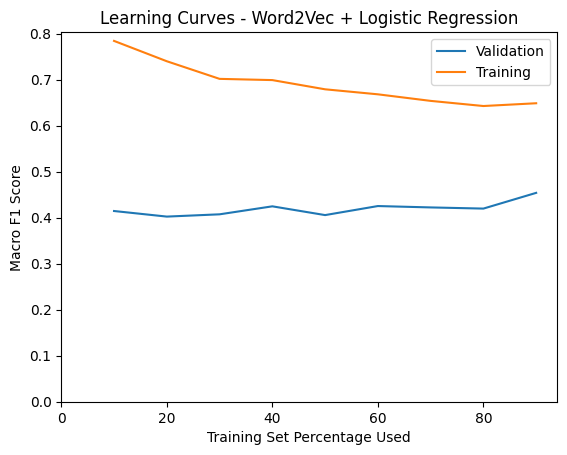

In [47]:
list_f1_word2vec = []
list_f1_train_word2vec = []
list_sample_size_word2vec = []

# Split once before the loop to get fixed validation raw text (train_df_val.concat)
# since each iteration trains a new word2vec model with different vectors,
# the validation text must be re-vectorized each time using that iteration's model.
# Splitting inside the loop would produce a different validation set each iteration,
# making F1 scores incomparable across iterations
train_df_learning_curves, train_df_val, _, _ = train_test_split(
    train_df, y_train_all,
    test_size=0.15,
    random_state=42,
    # preserve class distribution in the validation set
    stratify=y_train_all
)

# Learning curve: train the best word2vec + Logistic Regression model 9 times on growing subsets (10% to 90%) of training data
# to see how performance changes as more data is added
for times in range(9):
    X_subset, _, y_subset, _ = train_test_split(
        # pass train_df_learning_curves so X_subset retains the concat column needed to retrain word2vec on each subset
        # unlike TF-IDF we cannot use X_train_vec here because it is a numpy array of numbers with no raw text
        train_df_learning_curves,
        train_df_learning_curves['clarity_label'].values,
        test_size=1 - (times * 0.1 + 0.1),
        random_state=42,
        # use training labels to preserve class distribution in each subset
        stratify=train_df_learning_curves['clarity_label'].values
    )

    # Retrain word2vec on the subset
    word2vec_subset = gensim.models.Word2Vec(
        list(X_subset.concat.str.split()),
        vector_size = best_params['vector_size'],
        window = best_params['window'],
        min_count = 2,
        epochs = best_params['epochs'],
        sg = 1,
        seed = 42,
        workers = 1
    )

    def document_vector_subset(doc):
        """Create document vectors by averaging word vectors. Remove out-of-vocabulary words."""
        doc = [word for word in doc if word in word2vec_subset.wv.key_to_index]
        if not doc:
            return np.zeros(best_params['vector_size'])
        return np.mean(word2vec_subset.wv[doc], axis=0)

    # Vectorize subset and validation
    X_subset_vec = np.vstack(X_subset.concat.str.split().apply(document_vector_subset))
    X_val_learning_curves = np.vstack(train_df_val.concat.str.split().apply(document_vector_subset))

    clf = LogisticRegression(
        max_iter=10000,
        random_state=42,
        # use the best parameters found by GridSearch
        C=best_params['lr_params']['C'],
        solver=best_params['lr_params']['solver'],
        penalty=best_params['lr_params']['penalty'],
        class_weight=best_params['lr_params']['class_weight'],
    )
    clf.fit(X_subset_vec, y_subset)

    results_train = clf.predict(X_subset_vec)
    results_val = clf.predict(X_val_learning_curves)

    # average='macro' compute F1 per class then average equally, treating all 3 classes the same regardless of size
    f1_train = f1_score(y_subset, results_train, average='macro')
    f1_val = f1_score(y_val, results_val, average='macro')

    print(f"F1 Score: (train) {f1_train:.2f} vs {f1_val:.2f} (val)")

    list_f1_word2vec.append(f1_val)
    list_f1_train_word2vec.append(f1_train)
    list_sample_size_word2vec.append((times * 0.1 + 0.1) * 100)

plt.plot(list_sample_size_word2vec, list_f1_word2vec)
plt.plot(list_sample_size_word2vec, list_f1_train_word2vec)
plt.title("Learning Curves - Word2Vec + Logistic Regression")
plt.xlim(xmin=0)
plt.ylim(ymin=0)
plt.xlabel("Training Set Percentage Used")
plt.ylabel("Macro F1 Score")
plt.legend(["Validation", "Training"])
plt.show()

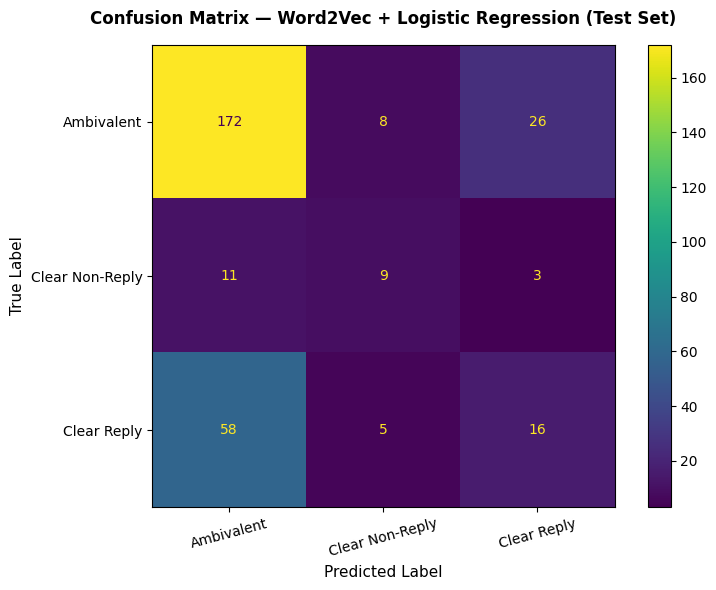



Confusion Matrix (raw counts):
Labels: ['Ambivalent', 'Clear Non-Reply', 'Clear Reply']
[[172   8  26]
 [ 11   9   3]
 [ 58   5  16]]


In [48]:
# Confusion Matrix Part: Word2Vec + Logistic Regression

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Get the true labels and predictions on the test set
y_true = test_df["clarity_label"]
y_pred = best_estimator.predict(best_X_test)

labels = ["Ambivalent", "Clear Non-Reply", "Clear Reply"]

# Compute the confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=labels)

# Plot the confusion matrix
fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(ax=ax, cmap="viridis", colorbar=True)

ax.set_title("Confusion Matrix — Word2Vec + Logistic Regression (Test Set)",
             fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel("Predicted Label", fontsize=11)
ax.set_ylabel("True Label", fontsize=11)

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

print("\n")
print("Confusion Matrix (raw counts):")
print(f"Labels: {labels}")
print(cm)

The following Heatmap and Grouped Bar Chart provide a visual representation of the results of the experiments for the Word2Vec model presented in the table below allowing for an easier comparison of the Validation Macro F1 scores across the different vector_size and epochs configurations. For more details about these see the report

| Vector Size | Epochs | Val Macro F1 |
|-------------|--------|--------------|
| 100 | 5 | 0.3946 |
| 100 | 10 | 0.4333 |
| 100 | 50 | 0.4119 |
| 300 | 5 | 0.4039 |
| 300 | 10 | 0.4382 |
| 300 | 20 | 0.4405 |
| 300 | 25 | 0.4441 |
| 300 | 30 | 0.4503 |
| 350 | 5 | 0.4146 |
| 350 | 10 | 0.4218 |
| 350 | 15 | 0.4391 |
| 350 | 20 | 0.4613 |
| 350 | 25 | 0.4559 |
| 350 | 30 | 0.4500 |
| 350 | 35 | 0.4584 |
| 400 | 15 | 0.4353 |
| 400 | 20 | 0.4560 |
| 400 | 25 | 0.4575 |
| 400 | 30 | 0.4861 |
| 400 | 35 | 0.4729 |
| 400 | 40 | 0.4798 |
| 450 | 25 | 0.4581 |
| 450 | 30 | 0.4508 |
| 450 | 35 | 0.4381 |
| 450 | 40 | 0.4378 |
| 500 | 25 | 0.4511 |
| 500 | 30 | 0.4602 |
| 500 | 35 | 0.4554 |
| 500 | 40 | 0.4526 |
| 600 | 25 | 0.4555 |
| 600 | 30 | 0.4562 |
| 600 | 35 | 0.4692 |
| 600 | 40 | 0.4735 |
| 600 | 45 | 0.4853 |
| 600 | 50 | 0.4621 |
| 600 | 55 | 0.4653 |
| 650 | 25 | 0.4615 |
| 650 | 30 | 0.4673 |
| 650 | 35 | 0.4740 |
| 650 | 40 | 0.4499 |
| 650 | 45 | 0.4550 |
| 650 | 50 | 0.4591 |
| 650 | 55 | 0.4510 |
| 650 | 60 | 0.4534 |
| 650 | 65 | 0.4611 |
| 650 | 70 | 0.4544 |
| 650 | 75 | 0.4559 |
| 650 | 80 | 0.4689 |
| 700 | 25 | 0.4690 |
| 700 | 30 | 0.4733 |
| 700 | 35 | 0.4883 |
| 700 | 40 | 0.4633 |
| 700 | 45 | 0.4933 |
| 700 | 50 | 0.4975 |
| 700 | 55 | 0.4961 |
| 700 | 60 | 0.4824 |
| 700 | 65 | 0.4639 |
| 700 | 70 | 0.4587 |
| 750 | 25 | 0.4451 |
| 750 | 30 | 0.4652 |
| 750 | 35 | 0.4672 |
| 750 | 40 | 0.4480 |
| 750 | 45 | 0.4588 |
| 750 | 50 | 0.4613 |
| 750 | 55 | 0.4950 |
| 750 | 60 | 0.4953 |
| 750 | 65 | 0.4945 |
| 750 | 70 | 0.4515 |
| 800 | 25 | 0.4628 |
| 800 | 30 | 0.4699 |
| 800 | 35 | 0.4720 |
| 800 | 40 | 0.4458 |
| 800 | 45 | 0.4507 |
| 800 | 50 | 0.4523 |
| 800 | 55 | 0.4477 |

In [49]:
# Heatmap: Experiments for Word2Vec Model

import plotly.graph_objects as go

rows = [
    (100,5,0.3946),(100,10,0.4333),(100,50,0.4119),
    (300,5,0.4039),(300,10,0.4382),(300,20,0.4405),(300,25,0.4441),(300,30,0.4503),
    (350,5,0.4146),(350,10,0.4218),(350,15,0.4391),(350,20,0.4613),(350,25,0.4559),(350,30,0.4500),(350,35,0.4584),
    (400,15,0.4353),(400,20,0.4560),(400,25,0.4575),(400,30,0.4861),(400,35,0.4729),(400,40,0.4798),
    (450,25,0.4581),(450,30,0.4508),(450,35,0.4381),(450,40,0.4378),
    (500,25,0.4511),(500,30,0.4602),(500,35,0.4554),(500,40,0.4526),
    (600,25,0.4555),(600,30,0.4562),(600,35,0.4692),(600,40,0.4735),(600,45,0.4853),(600,50,0.4621),(600,55,0.4653),
    (650,25,0.4615),(650,30,0.4673),(650,35,0.4740),(650,40,0.4499),(650,45,0.4550),(650,50,0.4591),
    (650,55,0.4510),(650,60,0.4534),(650,65,0.4611),(650,70,0.4544),(650,75,0.4559),(650,80,0.4689),
    (700,25,0.4690),(700,30,0.4733),(700,35,0.4883),(700,40,0.4633),(700,45,0.4933),(700,50,0.4975),
    (700,55,0.4961),(700,60,0.4824),(700,65,0.4639),(700,70,0.4587),
    (750,25,0.4451),(750,30,0.4652),(750,35,0.4672),(750,40,0.4480),(750,45,0.4588),(750,50,0.4613),
    (750,55,0.4950),(750,60,0.4953),(750,65,0.4945),(750,70,0.4515),
    (800,25,0.4628),(800,30,0.4699),(800,35,0.4720),(800,40,0.4458),(800,45,0.4507),(800,50,0.4523),(800,55,0.4477),
]

# Build lookup and axes
lookup = {(v, e): f1 for v, e, f1 in rows}
vsizes     = sorted(set(r[0] for r in rows))
epochs_all = sorted(set(r[1] for r in rows))

# Build matrix
matrix = []
for vs in vsizes:
    row = []
    for e in epochs_all:
        val = lookup.get((vs, e), None)
        row.append(round(val, 4) if val is not None else None)
    matrix.append(row)

fig2 = go.Figure(data=go.Heatmap(
    z=matrix,
    x=epochs_all,
    y=vsizes,
    colorscale='viridis',
    text=[[f'{v:.3f}' if v is not None else '' for v in row] for row in matrix],
    texttemplate='%{text}',
    textfont=dict(size=8),
    hoverongaps=False,
    hovertemplate='vector_size=%{y}<br>epochs=%{x}<br>Val F1=%{z:.4f}<extra></extra>',
    colorbar=dict(title='Val F1')
))

fig2.update_layout(
    title='Heatmap — Val Macro F1 by vector size and epochs',
    xaxis_title='Epochs',
    yaxis_title='Vector size',
    yaxis=dict(type='category'),
    template='plotly_white',
    height=500
)
fig2.show()

In [50]:
# Grouped Bar Chart: Experiments for Word2Vec Model

import plotly.graph_objects as go
from collections import defaultdict

rows = [
    (100,5,0.3946),(100,10,0.4333),(100,50,0.4119),
    (300,5,0.4039),(300,10,0.4382),(300,20,0.4405),(300,25,0.4441),(300,30,0.4503),
    (350,5,0.4146),(350,10,0.4218),(350,15,0.4391),(350,20,0.4613),(350,25,0.4559),(350,30,0.4500),(350,35,0.4584),
    (400,15,0.4353),(400,20,0.4560),(400,25,0.4575),(400,30,0.4861),(400,35,0.4729),(400,40,0.4798),
    (450,25,0.4581),(450,30,0.4508),(450,35,0.4381),(450,40,0.4378),
    (500,25,0.4511),(500,30,0.4602),(500,35,0.4554),(500,40,0.4526),
    (600,25,0.4555),(600,30,0.4562),(600,35,0.4692),(600,40,0.4735),(600,45,0.4853),(600,50,0.4621),(600,55,0.4653),
    (650,25,0.4615),(650,30,0.4673),(650,35,0.4740),(650,40,0.4499),(650,45,0.4550),(650,50,0.4591),
    (650,55,0.4510),(650,60,0.4534),(650,65,0.4611),(650,70,0.4544),(650,75,0.4559),(650,80,0.4689),
    (700,25,0.4690),(700,30,0.4733),(700,35,0.4883),(700,40,0.4633),(700,45,0.4933),(700,50,0.4975),
    (700,55,0.4961),(700,60,0.4824),(700,65,0.4639),(700,70,0.4587),
    (750,25,0.4451),(750,30,0.4652),(750,35,0.4672),(750,40,0.4480),(750,45,0.4588),(750,50,0.4613),
    (750,55,0.4950),(750,60,0.4953),(750,65,0.4945),(750,70,0.4515),
    (800,25,0.4628),(800,30,0.4699),(800,35,0.4720),(800,40,0.4458),(800,45,0.4507),(800,50,0.4523),(800,55,0.4477),
]

# Build lookup and sorted global axes
lookup = {(v, e): f1 for v, e, f1 in rows}
vsizes     = sorted(set(r[0] for r in rows))
all_epochs = sorted(set(r[1] for r in rows))  # global sorted epoch list

fig = go.Figure()

for vec in vsizes:
    # Align every trace to the same x-axis
    f1s  = [lookup.get((vec, e), None) for e in all_epochs]
    texts = [f"{v:.4f}" if v is not None else "" for v in f1s]

    fig.add_trace(go.Bar(
        name=str(vec),
        x=all_epochs,
        y=f1s,
        text=texts,
        textposition="outside",
        textfont=dict(size=7),
        marker=dict(
            line=dict(width=0.5, color="white"),
            opacity=0.9,
        ),
        hovertemplate=f"Vector size: {vec}<br>Epochs: %{{x}}<br>Val F1: %{{y:.4f}}<extra></extra>",
    ))

fig.update_layout(
    barmode="group",
    title="Grouped Bar Chart — Val Macro F1 by vector size and epochs",
    xaxis_title="Epochs",
    yaxis_title="Val Macro F1",
    yaxis=dict(range=[0.37, 0.52]),
    legend_title="Vector Size:",
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="right",
        x=1
    ),
    xaxis=dict(
        tickmode="array",
        tickvals=all_epochs,
        tickangle=-45,
        type="category",
    ),
    template="plotly_white",
    height=600,
    width=1400,
)

fig.show()